# EdgeTwin-XAI — Fixed & Reordered
Bugs fixed: undefined `y_prob`/`y_pred`, missing `estimate_rul`/`maintenance_schedule`, export-before-columns-exist, duplicate simulation function, Type label-encoding → one-hot.

## 1 — Setup & Load Data

In [2]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta

warnings.filterwarnings("ignore")
np.random.seed(42)
sns.set_style("whitegrid")

DATA_PATH = "ai4i2020.csv"   # change to "/content/ai4i2020.csv" on Colab
df = pd.read_csv(DATA_PATH)
print("Raw shape:", df.shape)
df.head()

Raw shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


## 2 — Clean & Encode Features
Fixed: `Type` now one-hot encoded instead of LabelEncoder (avoids implying H<L<M ordinality).

In [4]:
df = df.rename(columns={
    "Air temperature [K]":     "Air_temperature",
    "Process temperature [K]": "Process_temperature",
    "Rotational speed [rpm]":  "Rotational_speed",
    "Torque [Nm]":             "Torque",
    "Tool wear [min]":         "Tool_wear",
    "Machine failure":         "Machine_failure",
})
df = df.drop(columns=["UDI", "Product ID"], errors="ignore")

TYPE_CLASSES = sorted(df["Type"].unique().tolist())
df = pd.get_dummies(df, columns=["Type"], prefix="Type")

TYPE_COLS     = [f"Type_{t}" for t in TYPE_CLASSES]
FEATURES      = ["Air_temperature","Process_temperature",
                 "Rotational_speed","Torque","Tool_wear"] + TYPE_COLS
TARGET        = "Machine_failure"
FAILURE_MODES = ["TWF","HDF","PWF","OSF","RNF"]

X = df[FEATURES].copy()
y = df[TARGET].copy()
print("X:", X.shape, "| failure rate:", round(y.mean(), 4))
print("Type classes:", TYPE_CLASSES)
X.head()

X: (10000, 8) | failure rate: 0.0339
Type classes: ['H', 'L', 'M']


,Air_temperature,Process_temperature,Rotational_speed,Torque,Tool_wear,Type_H,Type_L,Type_M
0,298.1,308.6,1551,42.8,0,False,False,True
1,298.2,308.7,1408,46.3,3,False,True,False
2,298.1,308.5,1498,49.4,5,False,True,False
3,298.2,308.6,1433,39.5,7,False,True,False
4,298.2,308.7,1408,40.0,9,False,True,False


## 3 — EDA

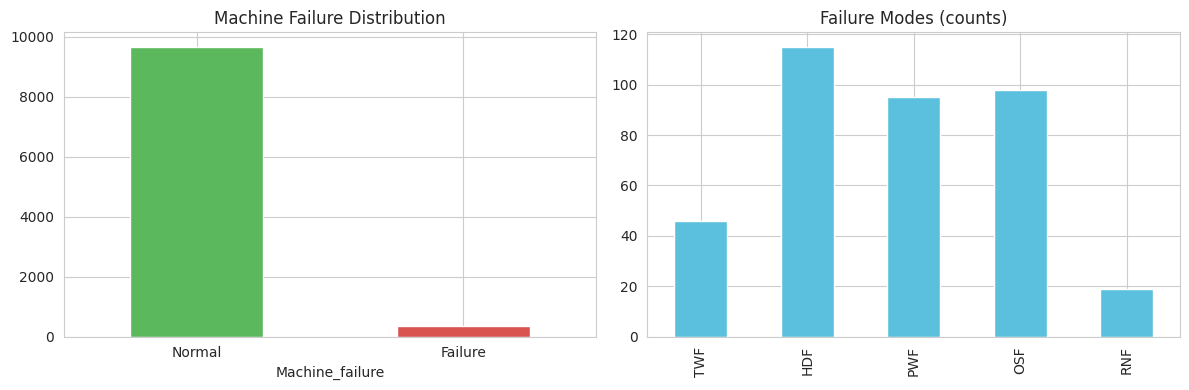

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df[TARGET].value_counts().plot(kind="bar", color=["#5cb85c","#d9534f"], ax=ax[0])
ax[0].set_title("Machine Failure Distribution")
ax[0].set_xticklabels(["Normal","Failure"], rotation=0)

mode_counts = df[FAILURE_MODES].sum()
mode_counts.plot(kind="bar", ax=ax[1], color="#5bc0de")
ax[1].set_title("Failure Modes (counts)")
plt.tight_layout(); plt.show()

## 4 — Train/Test Split + SMOTE

In [6]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)

from imblearn.over_sampling import SMOTE
sm = SMOTE(random_state=42)
X_train_res, y_train_res = sm.fit_resample(X_train, y_train)
print("After SMOTE:", X_train_res.shape, "| classes:", np.bincount(y_train_res))

After SMOTE: (15458, 8) | classes: [7729 7729]


## 5 — Train XGBoost
Fixed: `y_prob` is now defined right after training, before it's used anywhere.

In [7]:
from xgboost import XGBClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, accuracy_score, f1_score,
                             ConfusionMatrixDisplay, RocCurveDisplay,
                             precision_recall_curve)

xgb_model = XGBClassifier(
    n_estimators=300, max_depth=6, learning_rate=0.1,
    subsample=0.9, colsample_bytree=0.9,
    eval_metric="logloss", random_state=42, n_jobs=-1,
)
xgb_model.fit(X_train_res, y_train_res)

# FIX: y_prob must be computed before it's used anywhere below
y_prob = xgb_model.predict_proba(X_test)[:, 1]
print("✅ y_prob computed:", y_prob.shape)

✅ y_prob computed: (2000,)


## 6 — Threshold Optimisation
Fixed: `y_pred` (default 0.5 threshold) and `y_pred_opt` (best-F1 threshold) both now defined explicitly.

In [8]:
prec, rec, thr = precision_recall_curve(y_test, y_prob)
f1s = 2 * prec * rec / (prec + rec + 1e-12)
best_thr = float(thr[int(np.nanargmax(f1s[:-1]))])

# FIX: y_pred (default threshold) defined for the metrics that need it
y_pred     = (y_prob >= 0.5).astype(int)
y_pred_opt = (y_prob >= best_thr).astype(int)

print(f"Best F1 threshold = {best_thr:.3f}")
print(classification_report(y_test, y_pred_opt, target_names=["Normal","Failure"]))
print("ROC-AUC :", round(roc_auc_score(y_test, y_prob), 4))
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("F1      :", round(f1_score(y_test, y_pred), 4))

Best F1 threshold = 0.855
              precision    recall  f1-score   support

      Normal       0.99      1.00      0.99      1932
     Failure       0.85      0.69      0.76        68

    accuracy                           0.99      2000
   macro avg       0.92      0.84      0.88      2000
weighted avg       0.98      0.99      0.98      2000

ROC-AUC : 0.973
Accuracy: 0.975
F1      : 0.6835


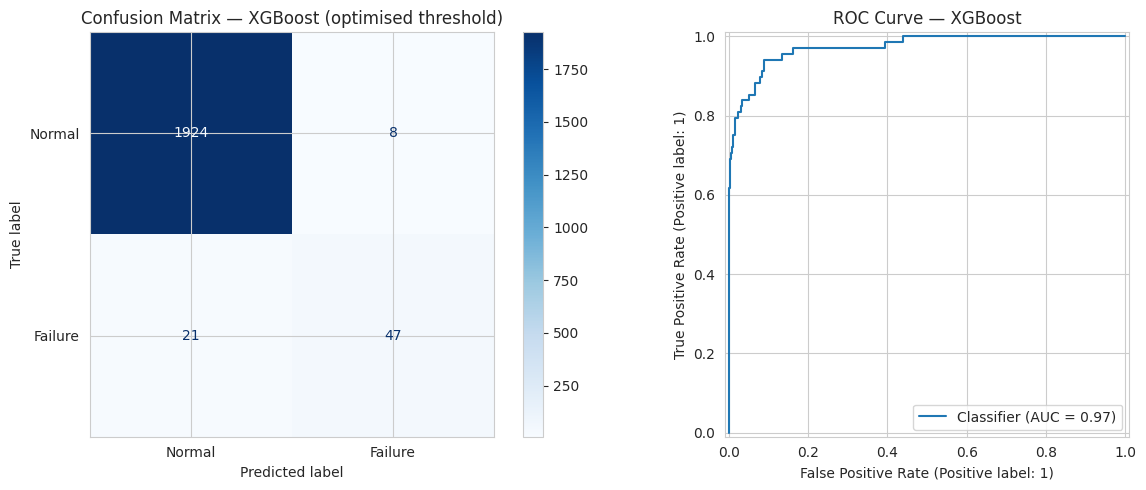

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_opt, ax=ax[0],
    display_labels=["Normal","Failure"], cmap="Blues")
ax[0].set_title("Confusion Matrix — XGBoost (optimised threshold)")
RocCurveDisplay.from_predictions(y_test, y_prob, ax=ax[1])
ax[1].set_title("ROC Curve — XGBoost")
plt.tight_layout(); plt.show()

## 7 — SHAP Explainability

SHAP shape: (2000, 8) | features: 8

Global feature importance (mean |SHAP|):
Torque                 2.355745
Tool_wear              2.152610
Rotational_speed       1.390207
Type_L                 1.343071
Air_temperature        1.112037
Type_M                 1.032466
Process_temperature    0.673679
Type_H                 0.440279
dtype: float32


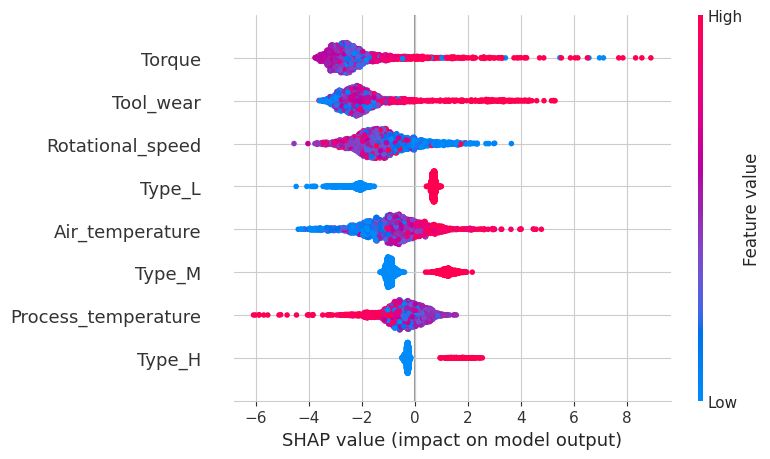

In [10]:
import shap
explainer   = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test)
print("SHAP shape:", np.array(shap_values).shape, "| features:", X_test.shape[1])

mean_abs = pd.Series(np.abs(shap_values).mean(axis=0),
                     index=FEATURES).sort_values(ascending=False)
print("\nGlobal feature importance (mean |SHAP|):")
print(mean_abs)
shap.summary_plot(shap_values, X_test, feature_names=FEATURES, show=True)

Highest-risk test row: idx=1225, prob=1.000, true=1


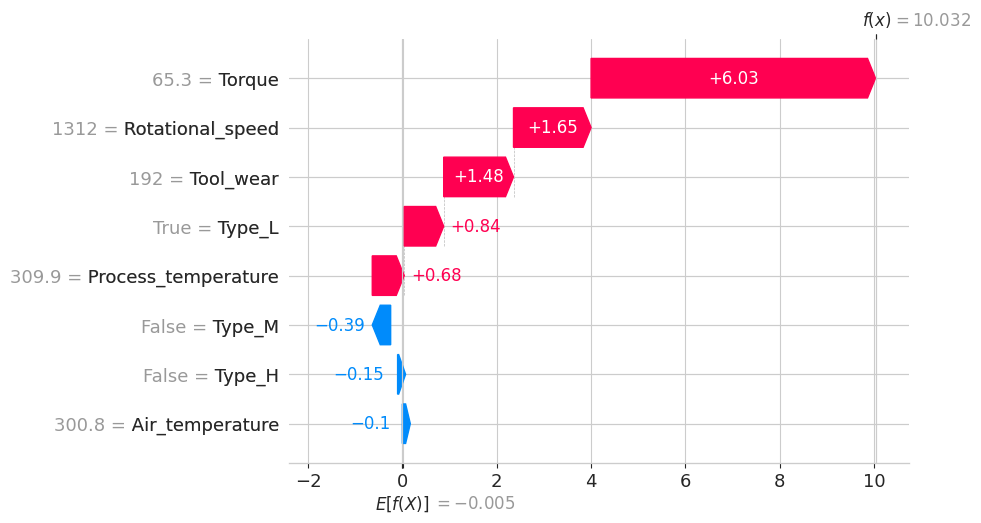

In [11]:
sample_idx = int(np.argmax(y_prob))   # highest-risk row in X_test
print(f"Highest-risk test row: idx={sample_idx}, "
      f"prob={y_prob[sample_idx]:.3f}, true={int(y_test.iloc[sample_idx])}")

shap.plots.waterfall(
    shap.Explanation(
        values       = shap_values[sample_idx],
        base_values  = explainer.expected_value,
        data         = X_test.iloc[sample_idx].values,
        feature_names= FEATURES,
    )
)

## 8 — Multi-Label Failure Mode Classifiers
Fixed: each mode classifier now trains/evaluates on the *same* `X_train`/`X_test` split as the main model (previously re-split per mode, leaking test rows from one split into the train set of another and making results inconsistent).

In [12]:
mode_models = {}
mode_train_idx = X_train.index
mode_test_idx  = X_test.index

for mode in FAILURE_MODES:
    ym_tr = df.loc[mode_train_idx, mode]
    ym_te = df.loc[mode_test_idx, mode]
    Xm_tr = X_train
    Xm_te = X_test

    pos = max(int(ym_tr.sum()), 1)
    neg = int((ym_tr == 0).sum())
    m = XGBClassifier(n_estimators=250, max_depth=5, learning_rate=0.1,
                      scale_pos_weight=neg/pos, eval_metric="logloss",
                      random_state=42, n_jobs=-1)
    m.fit(Xm_tr, ym_tr)
    auc = roc_auc_score(ym_te, m.predict_proba(Xm_te)[:,1]) if ym_te.sum() else float("nan")
    mode_models[mode] = m
    print(f"  {mode}: ROC-AUC={auc:.3f}  (train positives={int(ym_tr.sum())})")

  TWF: ROC-AUC=0.863  (train positives=36)
  HDF: ROC-AUC=0.999  (train positives=86)
  PWF: ROC-AUC=0.999  (train positives=82)
  OSF: ROC-AUC=1.000  (train positives=82)
  RNF: ROC-AUC=0.579  (train positives=15)


## 9 — Helper Functions (defined BEFORE they're used)
Fixed: `estimate_rul()` and `maintenance_schedule()` were called later in the original notebook but never defined anywhere — added here.

In [13]:
FEATURE_LABELS = {
    "Air_temperature":     "Air Temperature",
    "Process_temperature": "Process Temperature",
    "Rotational_speed":    "Rotational Speed",
    "Torque":              "Torque",
    "Tool_wear":           "Tool Wear",
}
for t in TYPE_CLASSES:
    FEATURE_LABELS[f"Type_{t}"] = f"Machine Type {t}"

RECO_MAP = {
    "Tool_wear":           "Replace cutting tool — wear threshold reached",
    "Torque":              "Inspect drive shaft & load balance",
    "Rotational_speed":    "Check bearings & spindle alignment",
    "Process_temperature": "Inspect cooling system & heat exchanger",
    "Air_temperature":     "Verify ambient airflow / ventilation",
}
for t in TYPE_CLASSES:
    RECO_MAP[f"Type_{t}"] = "Schedule type-specific preventive maintenance"

# UPGRADE 5: Explainable Recommendations — mapped from the dominant FAILURE MODE
# (TWF/HDF/PWF/OSF/RNF) rather than the generic top-SHAP-feature recommendation above.
# This produces human-readable, mode-specific maintenance actions.
MODE_RECO_MAP = {
    "TWF": "Tool replacement recommended — tool wear failure risk is dominant",
    "HDF": "Cooling system inspection recommended — heat dissipation failure risk is dominant",
    "PWF": "Power system inspection recommended — power failure risk is dominant",
    "OSF": "Load optimization recommended — overstrain failure risk is dominant",
    "RNF": "Sensor calibration recommended — random failure risk is dominant",
}

def status_from_score(score):
    if score >= 85: return "Healthy"
    if score >= 60: return "Warning"
    return "Critical"

def alert_from_risk(risk_pct):
    if risk_pct > 90: return "🚨 EMERGENCY"
    if risk_pct > 70: return "🔴 HIGH ALERT"
    if risk_pct > 40: return "🟠 WARNING"
    return "🟢 NORMAL"

def estimate_rul(health_score, max_hours=500.0):
    """FIX: was referenced but never defined. Simple monotonic mapping:
    100% health -> max_hours remaining, 0% health -> 0 hours remaining."""
    return round(max(health_score, 0) / 100.0 * max_hours, 1)

def maintenance_schedule(health_score):
    """FIX: was referenced but never defined."""
    if health_score > 80:  return "Routine (30-day check)"
    if health_score >= 60: return "Scheduled (14-day check)"
    if health_score >= 40: return "Priority (next maintenance window)"
    return "Immediate — stop & service"

def maintenance_cost(health):
    if health > 80:  return 0
    if health >= 60: return 200
    if health >= 40: return 500
    return 1000

def maintenance_days(health):
    if health > 80:  return 30
    if health >= 60: return 14
    return 0

def estimate_failure_date(rul_hours, ref=None):
    ref = ref or datetime.now()
    return (ref + timedelta(hours=float(rul_hours))).strftime("%Y-%m-%d")

# UPGRADE 1: Maintenance Priority Engine
def priority_from_prob(failure_prob_pct):
    """P1 = Failure Probability > 90%, P2 = > 70%, P3 = otherwise."""
    if failure_prob_pct > 90: return "P1"
    if failure_prob_pct > 70: return "P2"
    return "P3"

print("✅ Helper functions ready: estimate_rul, maintenance_schedule, "
      "maintenance_cost, maintenance_days, status_from_score, alert_from_risk, "
      "estimate_failure_date, priority_from_prob, MODE_RECO_MAP")

✅ Helper functions ready: estimate_rul, maintenance_schedule, maintenance_cost, maintenance_days, status_from_score, alert_from_risk, estimate_failure_date, priority_from_prob, MODE_RECO_MAP


## 10 — Build Digital Twin Table (single pass, all columns)
Fixed: previously the export cell referenced `Alert Level` and `Maintenance Cost` columns that were only added in a *later* cell — now every column is computed here, in one place, before anything reads from `digital_twin_df`.

In [14]:
all_prob   = xgb_model.predict_proba(X)[:,1]
all_health = (1 - all_prob) * 100

shap_all = explainer.shap_values(X)
top_idx  = np.abs(shap_all).argmax(axis=1)

root_causes = [FEATURE_LABELS[FEATURES[int(i)]] for i in top_idx]

mode_risks = {m: mm.predict_proba(X)[:,1]*100 for m, mm in mode_models.items()}

# UPGRADE 5: dominant failure mode per machine (highest predicted-risk mode),
# used to drive explainable, mode-specific recommendations instead of the
# generic top-SHAP-feature text.
mode_risk_matrix = np.column_stack([mode_risks[m] for m in FAILURE_MODES])
dominant_mode_idx = mode_risk_matrix.argmax(axis=1)
dominant_modes     = [FAILURE_MODES[i] for i in dominant_mode_idx]
recommendations    = [MODE_RECO_MAP[m] for m in dominant_modes]

digital_twin_df = pd.DataFrame({
    "Machine ID":          [f"M-{i:05d}" for i in range(len(X))],
    "Health Score":        np.round(all_health, 2),
    "Failure Probability": np.round(all_prob*100, 2),
    "Status":              [status_from_score(s) for s in all_health],
    "Dominant Mode":       dominant_modes,
    "Recommendation":      recommendations,
    "RUL":                 [estimate_rul(s) for s in all_health],
    "TWF Risk":            np.round(mode_risks["TWF"], 2),
    "HDF Risk":            np.round(mode_risks["HDF"], 2),
    "PWF Risk":            np.round(mode_risks["PWF"], 2),
    "OSF Risk":            np.round(mode_risks["OSF"], 2),
    "RNF Risk":            np.round(mode_risks["RNF"], 2),
    "Root Cause":          root_causes,
})

# All derived columns added immediately — no later cell depends on missing fields
digital_twin_df["Failure Date"]          = digital_twin_df["RUL"].apply(estimate_failure_date)
digital_twin_df["Alert"]                 = digital_twin_df["Failure Probability"].apply(alert_from_risk)
digital_twin_df["Maintenance Schedule"]  = digital_twin_df["Health Score"].apply(maintenance_schedule)
digital_twin_df["Days To Maintenance"]   = digital_twin_df["Health Score"].apply(maintenance_days)
digital_twin_df["Maintenance Cost"]      = digital_twin_df["Health Score"].apply(maintenance_cost)

# UPGRADE 1: Maintenance Priority Engine
digital_twin_df["Priority"] = digital_twin_df["Failure Probability"].apply(priority_from_prob)

print("Digital twin built:", digital_twin_df.shape)
digital_twin_df.head()

Digital twin built: (10000, 19)


,Machine ID,Health Score,Failure Probability,Status,Dominant Mode,Recommendation,RUL,TWF Risk,HDF Risk,PWF Risk,OSF Risk,RNF Risk,Root Cause,Failure Date,Alert,Maintenance Schedule,Days To Maintenance,Maintenance Cost,Priority
0,M-00000,100.000000,0.00,Healthy,PWF,Power system inspection recommended — power fa...,500.000000,0.00,0.0,0.03,0.0,0.00,Torque,2026-07-21,🟢 NORMAL,Routine (30-day check),30,0,P3
1,M-00001,99.980003,0.02,Healthy,RNF,Sensor calibration recommended — random failur...,499.899994,0.01,0.0,0.01,0.0,0.01,Tool Wear,2026-07-21,🟢 NORMAL,Routine (30-day check),30,0,P3
2,M-00002,99.989998,0.01,Healthy,PWF,Power system inspection recommended — power fa...,500.000000,0.00,0.0,0.01,0.0,0.00,Tool Wear,2026-07-21,🟢 NORMAL,Routine (30-day check),30,0,P3
3,M-00003,99.949997,0.05,Healthy,TWF,Tool replacement recommended — tool wear failu...,499.700012,0.01,0.0,0.00,0.0,0.00,Torque,2026-07-21,🟢 NORMAL,Routine (30-day check),30,0,P3
4,M-00004,99.980003,0.02,Healthy,TWF,Tool replacement recommended — tool wear failu...,499.899994,0.01,0.0,0.00,0.0,0.00,Torque,2026-07-21,🟢 NORMAL,Routine (30-day check),30,0,P3


## 10b — Fleet Risk Segmentation (Upgrade 2)
Buckets every machine into **Low / Medium / High** risk based on `Failure Probability`, and reports both the count and the percentage of fleet in each band.

Fleet Risk Segmentation:
  Low Risk    : 9621 machines  (96.2% of fleet)
  Medium Risk :   45 machines  (0.4% of fleet)
  High Risk   :  334 machines  (3.3% of fleet)


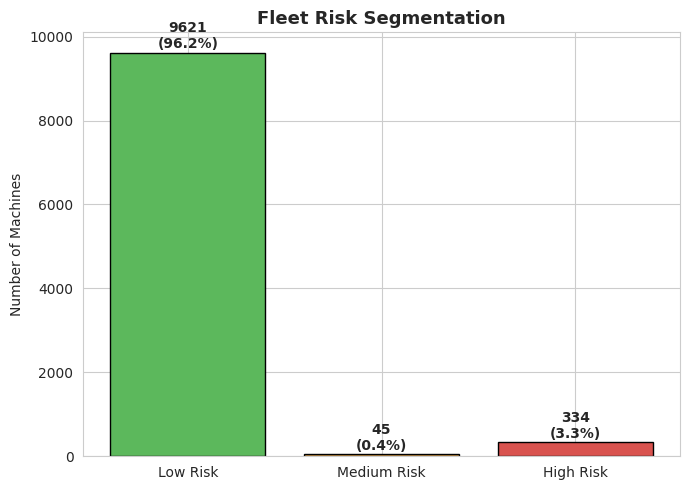

In [15]:
def risk_band(prob_pct):
    if prob_pct > 70:  return "High Risk"
    if prob_pct > 40:  return "Medium Risk"
    return "Low Risk"

digital_twin_df["Risk Segment"] = digital_twin_df["Failure Probability"].apply(risk_band)

risk_counts = digital_twin_df["Risk Segment"].value_counts().reindex(
    ["Low Risk","Medium Risk","High Risk"]).fillna(0).astype(int)
risk_pct = (risk_counts / len(digital_twin_df) * 100).round(1)

print("Fleet Risk Segmentation:")
for seg in ["Low Risk","Medium Risk","High Risk"]:
    print(f"  {seg:12s}: {risk_counts[seg]:4d} machines  ({risk_pct[seg]:.1f}% of fleet)")

fig, ax = plt.subplots(figsize=(7, 5))
colors = {"Low Risk":"#5cb85c", "Medium Risk":"#f0ad4e", "High Risk":"#d9534f"}
bars = ax.bar(risk_counts.index, risk_counts.values,
              color=[colors[s] for s in risk_counts.index], edgecolor="black")
for b, seg in zip(bars, risk_counts.index):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + max(risk_counts)*0.01,
            f"{risk_counts[seg]}\n({risk_pct[seg]:.1f}%)", ha="center", fontsize=10, fontweight="bold")
ax.set_title("Fleet Risk Segmentation", fontsize=13, fontweight="bold")
ax.set_ylabel("Number of Machines")
plt.tight_layout(); plt.show()

In [33]:
# NEW CELL — insert after cell 23
from sklearn.ensemble import IsolationForest

iso_forest = IsolationForest(n_estimators=200, contamination=0.05, random_state=42, n_jobs=-1)
iso_forest.fit(X)

# decision_function: higher = more normal. Flip sign so higher = more anomalous, then min-max to 0-100
raw_scores = -iso_forest.decision_function(X)
anomaly_score = (raw_scores - raw_scores.min()) / (raw_scores.max() - raw_scores.min()) * 100
anomaly_flag = (iso_forest.predict(X) == -1)  # True = anomalous

digital_twin_df["Anomaly Score"] = np.round(anomaly_score, 2)
digital_twin_df["Anomaly Flag"]  = np.where(anomaly_flag, "Anomalous", "Normal")

print(f"✅ Anomaly detection added | Anomalous machines: {anomaly_flag.sum()} / {len(X)}")
digital_twin_df[["Machine ID","Health Score","Failure Probability","Anomaly Score","Anomaly Flag"]].head()

✅ Anomaly detection added | Anomalous machines: 500 / 10000


,Machine ID,Health Score,Failure Probability,Anomaly Score,Anomaly Flag
0,M-00000,100.000000,0.00,36.84,Normal
1,M-00001,99.980003,0.02,20.35,Normal
2,M-00002,99.989998,0.01,23.43,Normal
3,M-00003,99.949997,0.05,18.29,Normal
4,M-00004,99.980003,0.02,17.94,Normal


In [34]:
# NEW CELL — insert after Upgrade 1 cell
# Hybrid Risk Score: weighted blend of three independent signals, normalized 0-100
W_FAILURE_PROB  = 0.5
W_HEALTH_DEFICIT = 0.3   # (100 - Health Score) → higher when health is low
W_ANOMALY        = 0.2

digital_twin_df["Hybrid Risk Score"] = np.round(
    W_FAILURE_PROB   * digital_twin_df["Failure Probability"] +
    W_HEALTH_DEFICIT * (100 - digital_twin_df["Health Score"]) +
    W_ANOMALY        * digital_twin_df["Anomaly Score"],
    2
)
digital_twin_df["Hybrid Risk Rank"] = digital_twin_df["Hybrid Risk Score"].rank(ascending=False, method="min").astype(int)

top10_hybrid = digital_twin_df.sort_values("Hybrid Risk Score", ascending=False).head(10)[
    ["Machine ID","Hybrid Risk Rank","Hybrid Risk Score","Failure Probability","Health Score","Anomaly Score","Anomaly Flag","Priority"]
]
print("Top 10 — Hybrid Risk Machines:")
display(top10_hybrid)

Top 10 — Hybrid Risk Machines:


,Machine ID,Hybrid Risk Rank,Hybrid Risk Score,Failure Probability,Health Score,Anomaly Score,Anomaly Flag,Priority
4997,M-04997,1,98.42,99.660004,0.34,93.48,Anomalous,P1
3867,M-03867,2,98.03,99.680000,0.32,91.44,Anomalous,P1
5334,M-05334,3,97.81,99.910004,0.09,89.39,Anomalous,P1
880,M-00880,4,97.57,99.580002,0.42,89.51,Anomalous,P1
4762,M-04762,5,97.56,99.919998,0.08,88.13,Anomalous,P1
847,M-00847,6,97.47,98.070000,1.93,95.07,Anomalous,P1
1095,M-01095,7,97.44,99.919998,0.08,87.54,Anomalous,P1
5048,M-05048,8,96.77,97.870003,2.13,92.38,Anomalous,P1
903,M-00903,9,96.65,97.730003,2.27,92.35,Anomalous,P1
7997,M-07997,10,96.52,99.690002,0.31,83.85,Anomalous,P1


## 10c — Dominant Failure Mode Analytics (Upgrade 3)
Identifies the most common failure mode across the fleet and what share of machines it affects.

KPI — Dominant Fleet Failure Mode: RNF (36.9% of machines)


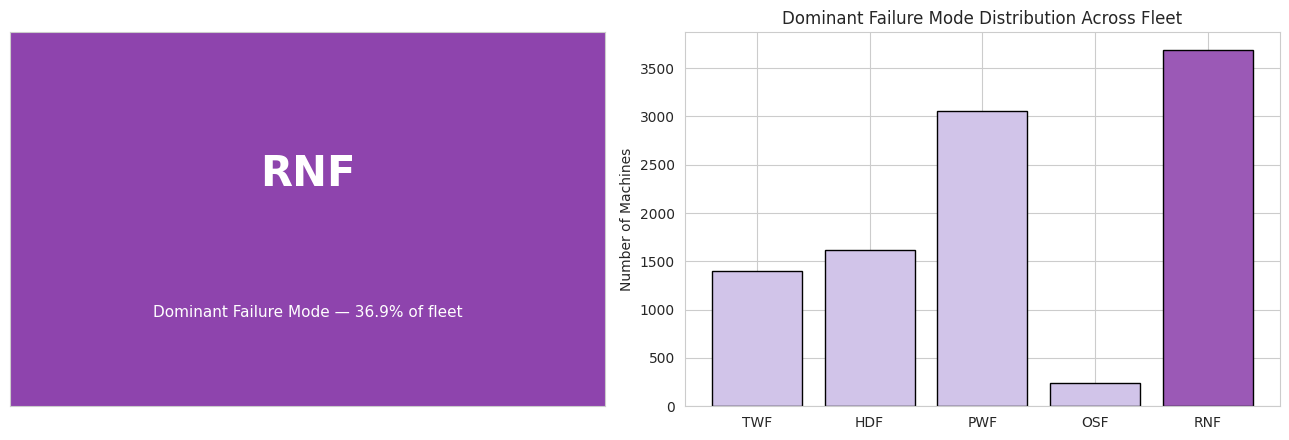

In [16]:
mode_counts = digital_twin_df["Dominant Mode"].value_counts().reindex(FAILURE_MODES).fillna(0).astype(int)
mode_pct    = (mode_counts / len(digital_twin_df) * 100).round(1)

dominant_fleet_mode     = mode_counts.idxmax()
dominant_fleet_mode_pct = mode_pct[dominant_fleet_mode]

print(f"KPI — Dominant Fleet Failure Mode: {dominant_fleet_mode} "
      f"({dominant_fleet_mode_pct:.1f}% of machines)")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# KPI card
ax[0].set_facecolor("#8e44ad"); ax[0].set_xticks([]); ax[0].set_yticks([])
ax[0].text(0.5, 0.62, dominant_fleet_mode, ha="center", va="center",
           fontsize=30, fontweight="bold", color="white", transform=ax[0].transAxes)
ax[0].text(0.5, 0.25, f"Dominant Failure Mode — {dominant_fleet_mode_pct:.1f}% of fleet",
           ha="center", va="center", fontsize=11, color="white", transform=ax[0].transAxes)

# Chart
bar_colors = ["#9b59b6" if m == dominant_fleet_mode else "#d1c4e9" for m in mode_counts.index]
ax[1].bar(mode_counts.index, mode_counts.values, color=bar_colors, edgecolor="black")
ax[1].set_title("Dominant Failure Mode Distribution Across Fleet")
ax[1].set_ylabel("Number of Machines")
plt.tight_layout(); plt.show()

## 10d — Maintenance Queue Ranking (Upgrade 4)
Sorts the fleet by **Failure Probability (desc) → Health Score (asc) → RUL (asc)** to produce a prioritized maintenance work queue, then shows the Top 10 machines needing immediate attention.

Top 10 — Maintenance Queue (immediate attention):


,Machine ID,Priority,Failure Probability,Health Score,RUL,Dominant Mode,Risk Segment,Recommendation
0,M-02761,P1,100.000000,0.00,0.0,OSF,High Risk,Load optimization recommended — overstrain fai...
1,M-04383,P1,100.000000,0.00,0.0,OSF,High Risk,Load optimization recommended — overstrain fai...
2,M-04417,P1,100.000000,0.00,0.0,HDF,High Risk,Cooling system inspection recommended — heat d...
3,M-04462,P1,100.000000,0.00,0.0,OSF,High Risk,Load optimization recommended — overstrain fai...
4,M-06497,P1,100.000000,0.00,0.0,OSF,High Risk,Load optimization recommended — overstrain fai...
5,M-03943,P1,99.989998,0.01,0.0,OSF,High Risk,Load optimization recommended — overstrain fai...
6,M-04729,P1,99.989998,0.01,0.0,OSF,High Risk,Load optimization recommended — overstrain fai...
7,M-07509,P1,99.989998,0.01,0.0,OSF,High Risk,Load optimization recommended — overstrain fai...
8,M-00069,P1,99.989998,0.01,0.1,OSF,High Risk,Load optimization recommended — overstrain fai...
9,M-01496,P1,99.989998,0.01,0.1,OSF,High Risk,Load optimization recommended — overstrain fai...


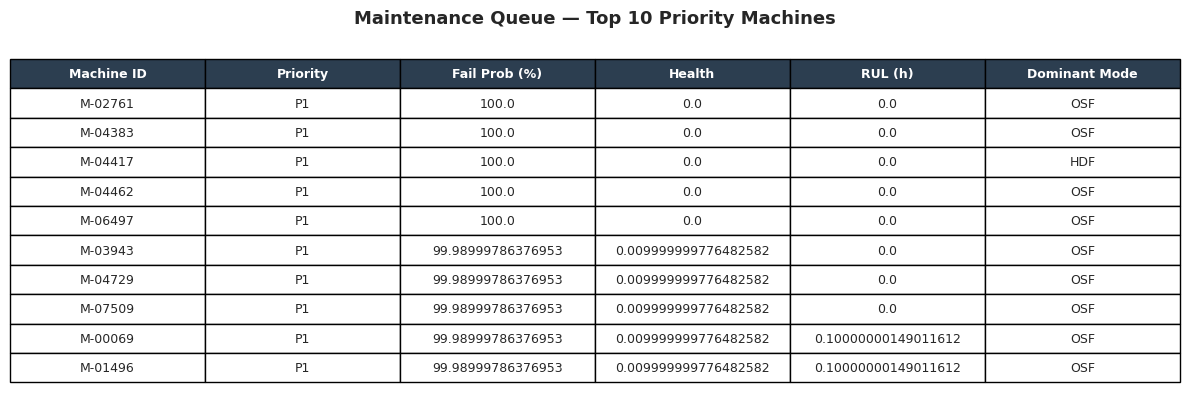

In [17]:
maintenance_queue = digital_twin_df.sort_values(
    by=["Failure Probability", "Health Score", "RUL"],
    ascending=[False, True, True]
).reset_index(drop=True)

top10_queue = maintenance_queue.head(10)[[
    "Machine ID","Priority","Failure Probability","Health Score","RUL",
    "Dominant Mode","Risk Segment","Recommendation"
]]

print("Top 10 — Maintenance Queue (immediate attention):")
display(top10_queue)

fig, ax = plt.subplots(figsize=(12, 4.2))
ax.axis("off")
tbl = ax.table(
    cellText=top10_queue[["Machine ID","Priority","Failure Probability","Health Score","RUL","Dominant Mode"]].values,
    colLabels=["Machine ID","Priority","Fail Prob (%)","Health","RUL (h)","Dominant Mode"],
    cellLoc="center", loc="center"
)
tbl.auto_set_font_size(False); tbl.set_fontsize(9); tbl.scale(1, 1.6)
for j in range(6):
    tbl[(0, j)].set_facecolor("#2c3e50")
    tbl[(0, j)].set_text_props(color="white", fontweight="bold")
ax.set_title("Maintenance Queue — Top 10 Priority Machines", fontsize=13, fontweight="bold", pad=14)
plt.tight_layout(); plt.show()

## 11 — Root Cause Ranking Helper

In [18]:
def rank_root_causes(machine_idx, top_n=3):
    """Return (ranked_list, primary, pretty_report) for a single machine."""
    risks  = {m: float(mode_risks[m][machine_idx]) for m in FAILURE_MODES}
    ranked = sorted(risks.items(), key=lambda x: x[1], reverse=True)[:top_n]
    primary = ranked[0][0]
    lines  = [f"{i+1}. {m} = {v:.1f}%" for i, (m, v) in enumerate(ranked)]
    return ranked, primary, "\n".join(lines)

def root_cause_report(machine_idx, machine_id):
    ranked, primary, body = rank_root_causes(machine_idx)
    return (f"## {machine_id}\n{body}\n\nPrimary Cause = {primary}")

# FIX: previously guarded on a not-yet-defined `all_prob` via globals(); all_prob is
# now guaranteed to exist from Section 10, so we use it directly.
demo_idx = int(np.argmax(all_prob))
print(root_cause_report(demo_idx, f"M-{demo_idx:05d}"))

## M-04383
1. OSF = 100.0%
2. HDF = 100.0%
3. PWF = 1.9%

Primary Cause = OSF


## 12 — RUL & Risk Trend Charts

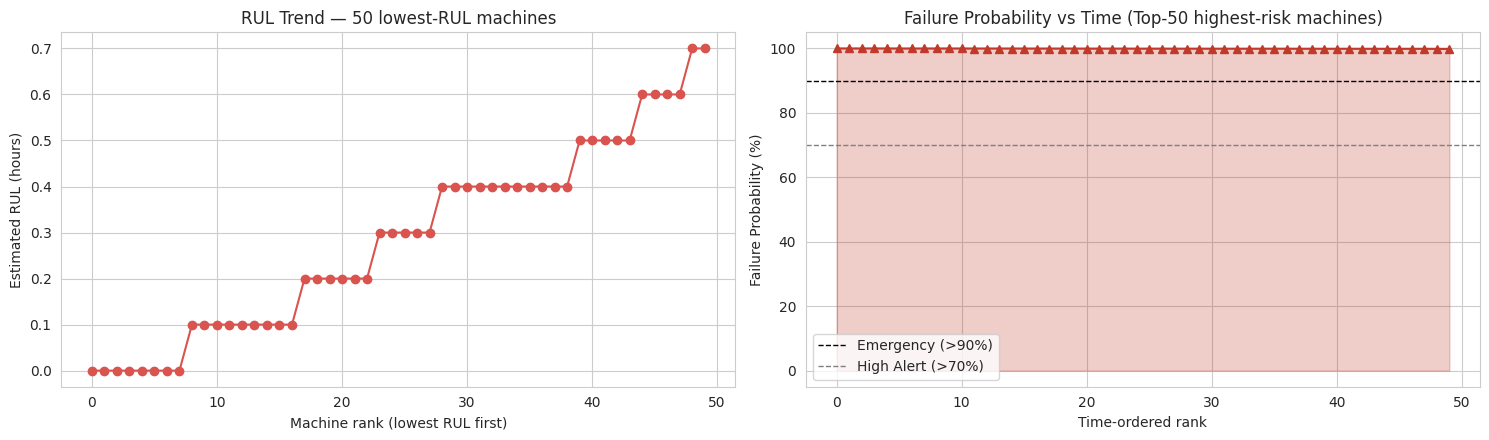

In [19]:
sample = digital_twin_df.sort_values("RUL").head(50).reset_index(drop=True)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))

ax[0].plot(sample.index, sample["RUL"], marker="o", color="#d9534f")
ax[0].set_title("RUL Trend — 50 lowest-RUL machines")
ax[0].set_xlabel("Machine rank (lowest RUL first)")
ax[0].set_ylabel("Estimated RUL (hours)")

risk_sample = digital_twin_df.sort_values("Failure Probability", ascending=False).head(50).reset_index(drop=True)
ax[1].plot(risk_sample.index, risk_sample["Failure Probability"], marker="^", color="#c0392b")
ax[1].fill_between(risk_sample.index, risk_sample["Failure Probability"], alpha=0.25, color="#c0392b")
ax[1].axhline(90, ls="--", color="black", lw=1, label="Emergency (>90%)")
ax[1].axhline(70, ls="--", color="gray",  lw=1, label="High Alert (>70%)")
ax[1].set_title("Failure Probability vs Time (Top-50 highest-risk machines)")
ax[1].set_xlabel("Time-ordered rank")
ax[1].set_ylabel("Failure Probability (%)")
ax[1].legend(loc="lower left")

plt.tight_layout(); plt.show()

## 13 — Live Single-Machine Prediction
Fixed: now includes basic input range validation against training data, and `Type` handling matches the one-hot scheme from Section 2 instead of `LabelEncoder`.

In [20]:
FEATURE_RANGES = {c: (X[c].min(), X[c].max()) for c in
    ["Air_temperature","Process_temperature","Rotational_speed","Torque","Tool_wear"]}

def validate_inputs(air_temp, proc_temp, rot_speed, torque, tool_wear):
    vals = {"Air_temperature": air_temp, "Process_temperature": proc_temp,
            "Rotational_speed": rot_speed, "Torque": torque, "Tool_wear": tool_wear}
    warnings_out = []
    for k, v in vals.items():
        lo, hi = FEATURE_RANGES[k]
        if v < lo or v > hi:
            warnings_out.append(f"⚠️ {k}={v} outside training range [{lo:.1f}, {hi:.1f}]")
    return warnings_out

def predict_machine(type_str, air_temp, proc_temp, rot_speed, torque, tool_wear):
    t = str(type_str).strip().upper()
    if t not in TYPE_CLASSES:
        raise ValueError(f"Type must be one of {TYPE_CLASSES}")

    warns = validate_inputs(air_temp, proc_temp, rot_speed, torque, tool_wear)
    if warns:
        for w in warns:
            print(w)

    row = {f: 0 for f in TYPE_COLS}
    row[f"Type_{t}"] = 1
    row.update({
        "Air_temperature":     float(air_temp),
        "Process_temperature": float(proc_temp),
        "Rotational_speed":    float(rot_speed),
        "Torque":              float(torque),
        "Tool_wear":           float(tool_wear),
    })
    new_machine = pd.DataFrame([row])[FEATURES]

    prob   = float(xgb_model.predict_proba(new_machine)[0, 1])
    health = (1 - prob) * 100
    status = status_from_score(health)
    rul    = estimate_rul(health)
    mode_pred = {m: round(float(mm.predict_proba(new_machine)[0, 1] * 100), 2)
                 for m, mm in mode_models.items()}

    # UPGRADE 5: recommendation driven by dominant failure mode (consistent with
    # the fleet-level digital_twin_df logic), instead of generic top-SHAP-feature text.
    dominant_mode = max(mode_pred, key=mode_pred.get)

    sv       = explainer.shap_values(new_machine)[0]
    top_feat = FEATURES[int(np.argmax(np.abs(sv)))]

    return {
        "Failure Probability (%)": round(prob * 100, 2),
        "Health Score":            round(health, 2),
        "Status":                  status,
        "Priority":                priority_from_prob(round(prob * 100, 2)),
        "Estimated RUL (hours)":   rul,
        "Failure Mode Risks (%)":  mode_pred,
        "Dominant Mode":           dominant_mode,
        "Root Cause":              FEATURE_LABELS[top_feat],
        "Recommendation":          MODE_RECO_MAP[dominant_mode],
    }

predict_machine("M", 300.0, 310.0, 1500, 40.0, 50.0)

{'Failure Probability (%)': 0.02,
 'Health Score': 99.98,
 'Status': 'Healthy',
 'Priority': 'P3',
 'Estimated RUL (hours)': 499.9,
 'Failure Mode Risks (%)': {'TWF': 0.0,
  'HDF': 0.0,
  'PWF': 0.0,
  'OSF': 0.0,
  'RNF': 0.0},
 'Dominant Mode': 'TWF',
 'Root Cause': 'Torque',
 'Recommendation': 'Tool replacement recommended — tool wear failure risk is dominant'}

In [21]:
def predict_from_input():
    print("--- EdgeTwin-XAI Live Prediction ---")
    t  = input(f"Type {TYPE_CLASSES}: ")
    at = float(input("Air Temperature (K): "))
    pt = float(input("Process Temperature (K): "))
    rs = float(input("Rotational Speed (rpm): "))
    tq = float(input("Torque (Nm): "))
    tw = float(input("Tool Wear (min): "))
    out = predict_machine(t, at, pt, rs, tq, tw)
    for k, v in out.items():
        print(f"  {k}: {v}")
    return out

## 14 — Interactive Widget Panel

In [22]:
import ipywidgets as widgets
from IPython.display import display, clear_output

w_type   = widgets.Dropdown(options=TYPE_CLASSES, value=TYPE_CLASSES[0], description="Type:")
w_air    = widgets.FloatSlider(value=300.0, min=295.0, max=305.0, step=0.1, description="Air T (K):")
w_proc   = widgets.FloatSlider(value=310.0, min=305.0, max=315.0, step=0.1, description="Proc T (K):")
w_rot    = widgets.IntSlider(  value=1500,  min=1100,  max=2900,  step=10,  description="Rot (rpm):")
w_torque = widgets.FloatSlider(value=40.0,  min=3.0,   max=80.0,  step=0.5, description="Torque (Nm):")
w_wear   = widgets.IntSlider(  value=50,    min=0,     max=260,   step=1,   description="Tool wear (min):")
btn      = widgets.Button(description="Predict", button_style="primary")
out_area = widgets.Output()

def on_predict(_):
    with out_area:
        clear_output()
        r = predict_machine(w_type.value, w_air.value, w_proc.value,
                            w_rot.value, w_torque.value, w_wear.value)
        print("=== EdgeTwin-XAI Prediction ===")
        for k, v in r.items():
            print(f"  {k}: {v}")

btn.on_click(on_predict)
display(widgets.VBox([w_type, w_air, w_proc, w_rot, w_torque, w_wear, btn, out_area]))

## 15 — Fleet KPI Dashboard

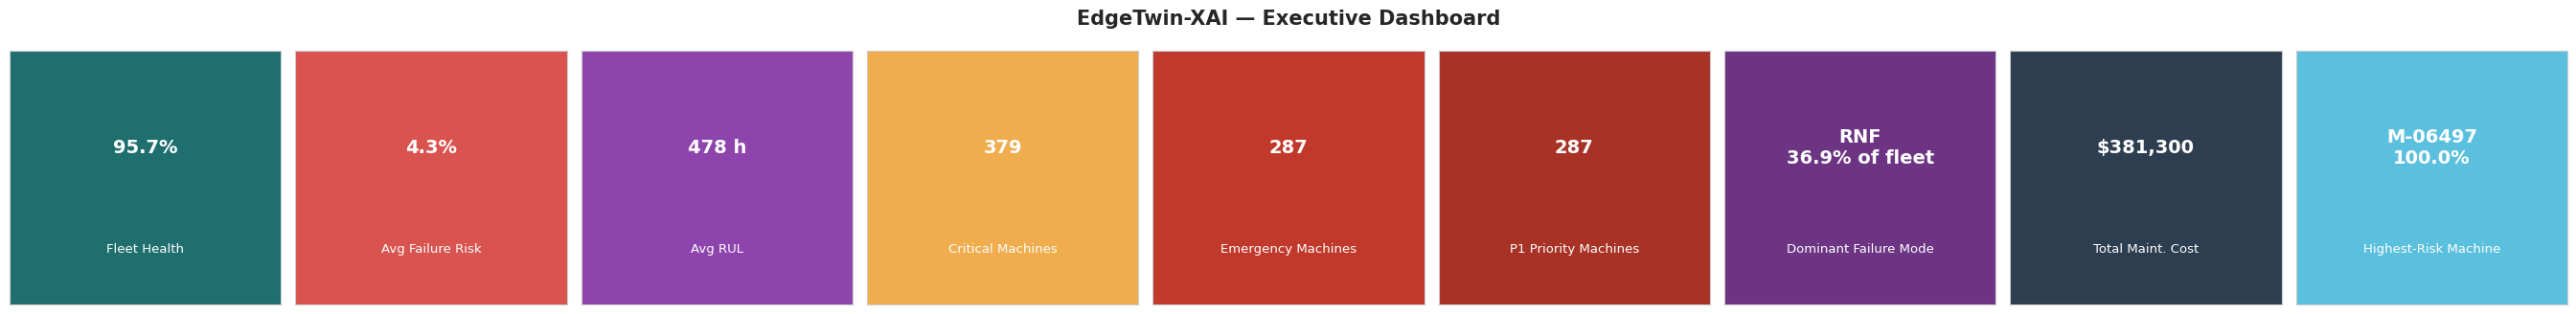

Fleet Health: 95.7% | Avg Risk: 4.3% | Avg RUL: 478h | Critical: 379 | Emergency: 287 | P1 Priority: 287 | Dominant Mode: RNF (36.9%) | Maint. Cost: $381,300


In [23]:
fleet_health   = digital_twin_df["Health Score"].mean()
avg_risk       = digital_twin_df["Failure Probability"].mean()
avg_rul        = digital_twin_df["RUL"].mean()
n_critical     = int((digital_twin_df["Status"] == "Critical").sum())
n_emergency    = int(digital_twin_df["Alert"].str.contains("EMERGENCY").sum())
total_cost     = int(digital_twin_df["Maintenance Cost"].sum())
top_machine    = digital_twin_df.sort_values("Failure Probability", ascending=False).iloc[0]

# UPGRADE 1: Priority counts for dashboard tile
n_p1 = int((digital_twin_df["Priority"] == "P1").sum())

# UPGRADE 3: dominant fleet failure mode for dashboard tile
_dom_mode_counts = digital_twin_df["Dominant Mode"].value_counts()
dominant_fleet_mode     = _dom_mode_counts.idxmax()
dominant_fleet_mode_pct = round(_dom_mode_counts.max() / len(digital_twin_df) * 100, 1)

tiles = [
    ("Fleet Health",          f"{fleet_health:.1f}%",                                    "#1f6f6f"),
    ("Avg Failure Risk",      f"{avg_risk:.1f}%",                                        "#d9534f"),
    ("Avg RUL",               f"{avg_rul:.0f} h",                                        "#8e44ad"),
    ("Critical Machines",     f"{n_critical}",                                           "#f0ad4e"),
    ("Emergency Machines",    f"{n_emergency}",                                          "#c0392b"),
    ("P1 Priority Machines",  f"{n_p1}",                                                 "#a93226"),
    ("Dominant Failure Mode", f"{dominant_fleet_mode}\n{dominant_fleet_mode_pct:.1f}% of fleet", "#6c3483"),
    ("Total Maint. Cost",     f"${total_cost:,}",                                        "#2c3e50"),
    ("Highest-Risk Machine",  f"{top_machine['Machine ID']}\n{top_machine['Failure Probability']:.1f}%", "#5bc0de"),
]

fig, axes = plt.subplots(1, len(tiles), figsize=(3.0*len(tiles), 3.3))
for ax, (label, value, color) in zip(axes, tiles):
    ax.set_facecolor(color); ax.set_xticks([]); ax.set_yticks([])
    ax.text(0.5, 0.62, value, ha="center", va="center",
            fontsize=14, fontweight="bold", color="white", transform=ax.transAxes)
    ax.text(0.5, 0.22, label, ha="center", va="center",
            fontsize=9.5, color="white", transform=ax.transAxes)
plt.suptitle("EdgeTwin-XAI — Executive Dashboard", fontsize=15, fontweight="bold")
plt.tight_layout(); plt.show()

print(f"Fleet Health: {fleet_health:.1f}% | Avg Risk: {avg_risk:.1f}% | "
      f"Avg RUL: {avg_rul:.0f}h | Critical: {n_critical} | "
      f"Emergency: {n_emergency} | P1 Priority: {n_p1} | "
      f"Dominant Mode: {dominant_fleet_mode} ({dominant_fleet_mode_pct:.1f}%) | "
      f"Maint. Cost: ${total_cost:,}")

## 15b — Executive Summary Generator (Upgrade 6)
Auto-generates a one-paragraph management summary from the live fleet metrics, and exports it to a `.txt` file alongside the CSV.

In [24]:
def generate_executive_summary():
    fhi          = digital_twin_df["Health Score"].mean()
    n_crit       = int((digital_twin_df["Status"] == "Critical").sum())
    dom_counts   = digital_twin_df["Dominant Mode"].value_counts()
    dom_mode     = dom_counts.idxmax()
    dom_pct      = round(dom_counts.max() / len(digital_twin_df) * 100, 1)
    total_cost   = int(digital_twin_df["Maintenance Cost"].sum())
    top_machine  = digital_twin_df.sort_values("Failure Probability", ascending=False).iloc[0]
    n_p1         = int((digital_twin_df["Priority"] == "P1").sum())

    summary = (
        f"Fleet Health Index = {fhi:.1f}. "
        f"{n_crit} machines are critical, including {n_p1} at Priority P1. "
        f"{dom_mode} is the dominant failure mode, affecting {dom_pct:.1f}% of the fleet. "
        f"Estimated maintenance cost = ${total_cost:,}. "
        f"Top priority machine = {top_machine['Machine ID']} "
        f"(Failure Probability {top_machine['Failure Probability']:.1f}%)."
    )
    return summary

executive_summary = generate_executive_summary()
print("=== Executive Summary ===")
print(executive_summary)

with open("EdgeTwin_Executive_Summary.txt", "w") as f:
    f.write(executive_summary)
print("\n✅ Saved EdgeTwin_Executive_Summary.txt")

=== Executive Summary ===
Fleet Health Index = 95.7. 379 machines are critical, including 287 at Priority P1. RNF is the dominant failure mode, affecting 36.9% of the fleet. Estimated maintenance cost = $381,300. Top priority machine = M-06497 (Failure Probability 100.0%).

✅ Saved EdgeTwin_Executive_Summary.txt


## 16 — Fleet Status & Health Distribution

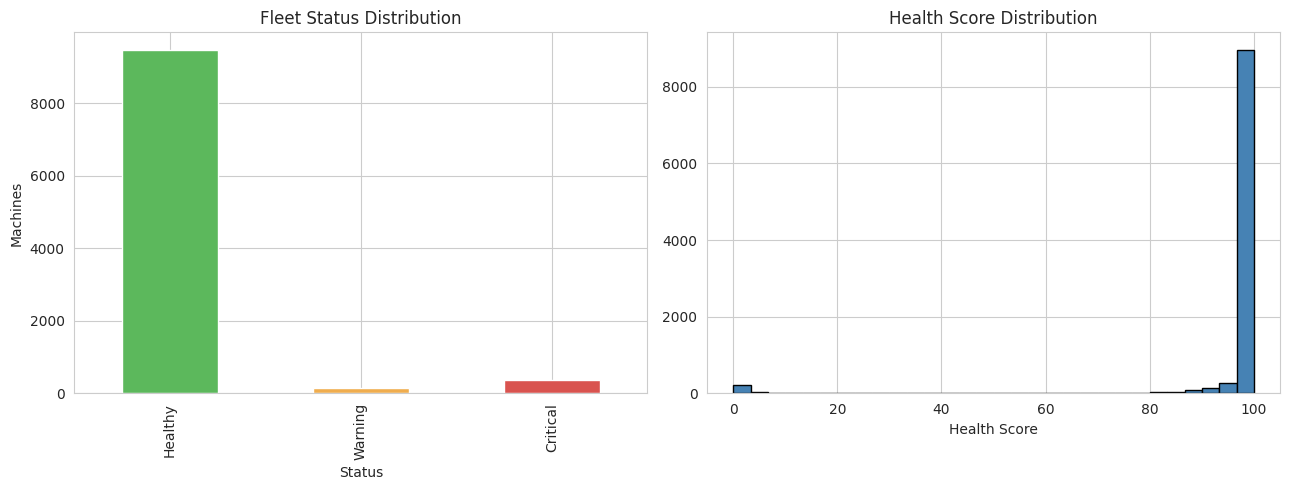

Top-10 Highest-Risk Machines:


,Machine ID,Health Score,Failure Probability,Status,Dominant Mode,Recommendation,RUL,TWF Risk,HDF Risk,PWF Risk,OSF Risk,RNF Risk,Root Cause,Failure Date,Alert,Maintenance Schedule,Days To Maintenance,Maintenance Cost,Priority,Risk Segment
6497,M-06497,0.00,100.000000,Critical,OSF,Load optimization recommended — overstrain fai...,0.0,0.01,8.070000,96.620003,100.00,0.01,Torque,2026-06-30,🚨 EMERGENCY,Immediate — stop & service,0,1000,P1,High Risk
4383,M-04383,0.00,100.000000,Critical,OSF,Load optimization recommended — overstrain fai...,0.0,0.09,99.970001,1.860000,100.00,0.10,Torque,2026-06-30,🚨 EMERGENCY,Immediate — stop & service,0,1000,P1,High Risk
2761,M-02761,0.00,100.000000,Critical,OSF,Load optimization recommended — overstrain fai...,0.0,0.10,0.110000,0.820000,100.00,0.01,Torque,2026-06-30,🚨 EMERGENCY,Immediate — stop & service,0,1000,P1,High Risk
4462,M-04462,0.00,100.000000,Critical,OSF,Load optimization recommended — overstrain fai...,0.0,0.01,99.989998,17.760000,100.00,0.09,Torque,2026-06-30,🚨 EMERGENCY,Immediate — stop & service,0,1000,P1,High Risk
4417,M-04417,0.00,100.000000,Critical,HDF,Cooling system inspection recommended — heat d...,0.0,0.01,100.000000,99.970001,1.28,0.02,Torque,2026-06-30,🚨 EMERGENCY,Immediate — stop & service,0,1000,P1,High Risk
1496,M-01496,0.01,99.989998,Critical,OSF,Load optimization recommended — overstrain fai...,0.1,0.02,0.070000,99.949997,100.00,0.00,Torque,2026-06-30,🚨 EMERGENCY,Immediate — stop & service,0,1000,P1,High Risk
69,M-00069,0.01,99.989998,Critical,OSF,Load optimization recommended — overstrain fai...,0.1,0.00,0.000000,99.989998,100.00,0.20,Torque,2026-06-30,🚨 EMERGENCY,Immediate — stop & service,0,1000,P1,High Risk
4729,M-04729,0.01,99.989998,Critical,OSF,Load optimization recommended — overstrain fai...,0.0,0.14,99.980003,0.060000,100.00,0.07,Torque,2026-06-30,🚨 EMERGENCY,Immediate — stop & service,0,1000,P1,High Risk
7509,M-07509,0.01,99.989998,Critical,OSF,Load optimization recommended — overstrain fai...,0.0,0.10,0.000000,0.090000,100.00,0.01,Torque,2026-06-30,🚨 EMERGENCY,Immediate — stop & service,0,1000,P1,High Risk
3943,M-03943,0.01,99.989998,Critical,OSF,Load optimization recommended — overstrain fai...,0.0,0.18,0.040000,99.949997,100.00,0.08,Torque,2026-06-30,🚨 EMERGENCY,Immediate — stop & service,0,1000,P1,High Risk


In [25]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
digital_twin_df["Status"].value_counts()\
    .reindex(["Healthy","Warning","Critical"])\
    .plot(kind="bar", color=["#5cb85c","#f0ad4e","#d9534f"], ax=ax[0])
ax[0].set_title("Fleet Status Distribution"); ax[0].set_ylabel("Machines")

ax[1].hist(digital_twin_df["Health Score"], bins=30, color="steelblue", edgecolor="black")
ax[1].set_title("Health Score Distribution"); ax[1].set_xlabel("Health Score")
plt.tight_layout(); plt.show()

print("Top-10 Highest-Risk Machines:")
digital_twin_df.sort_values("Failure Probability", ascending=False).head(10)

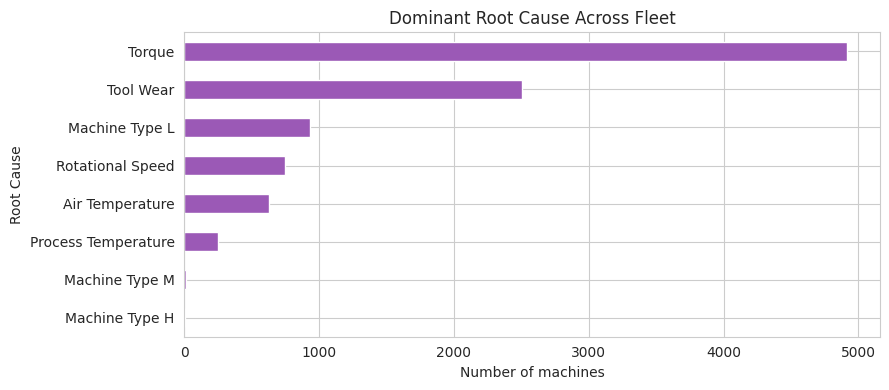

In [26]:
rc_counts = digital_twin_df["Root Cause"].value_counts()
plt.figure(figsize=(9,4))
rc_counts.plot(kind="barh", color="#9b59b6")
plt.title("Dominant Root Cause Across Fleet")
plt.xlabel("Number of machines"); plt.gca().invert_yaxis()
plt.tight_layout(); plt.show()

## 17 — Industrial Digital Twin Detail Screen

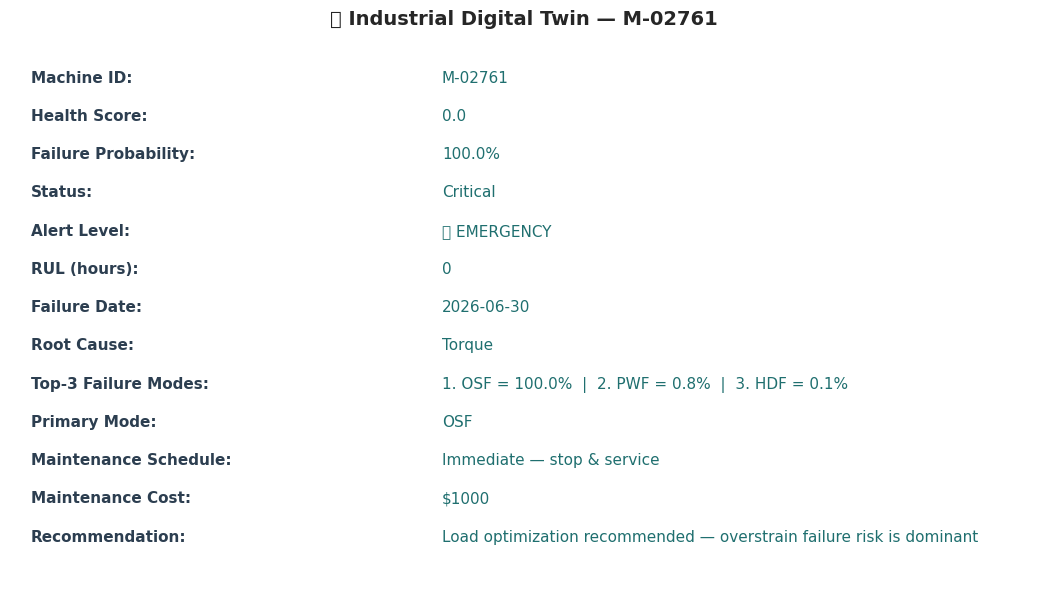

In [27]:
def render_digital_twin(machine_idx):
    row = digital_twin_df.iloc[machine_idx]
    ranked, primary, body = rank_root_causes(machine_idx)

    panel = [
        ("Machine ID",          row["Machine ID"]),
        ("Health Score",        f"{row['Health Score']:.1f}"),
        ("Failure Probability", f"{row['Failure Probability']:.1f}%"),
        ("Status",              row["Status"]),
        ("Alert Level",         row["Alert"]),
        ("RUL (hours)",         f"{row['RUL']:.0f}"),
        ("Failure Date",        row["Failure Date"]),
        ("Root Cause",          row["Root Cause"]),
        ("Top-3 Failure Modes", body.replace("\n", "  |  ")),
        ("Primary Mode",        primary),
        ("Maintenance Schedule",row["Maintenance Schedule"]),
        ("Maintenance Cost",    f"${int(row['Maintenance Cost'])}"),
        ("Recommendation",      row["Recommendation"]),
    ]
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.set_xlim(0,1); ax.set_ylim(0,len(panel)+1); ax.set_axis_off()
    ax.set_title(f"🛰️ Industrial Digital Twin — {row['Machine ID']}",
                 fontsize=14, fontweight="bold", pad=14)
    for i, (k, v) in enumerate(panel):
        y = len(panel) - i
        ax.text(0.02, y, f"{k}:", fontsize=11, fontweight="bold", color="#2c3e50")
        ax.text(0.42, y, str(v),  fontsize=11, color="#1f6f6f")
    plt.tight_layout(); plt.show()

worst_idx = int(digital_twin_df["Failure Probability"].idxmax())
render_digital_twin(worst_idx)

## 18 — Real-Time Simulation
Fixed: the function was previously defined twice, with a duplicated/copy-pasted top-3 ranking block inside the loop. Now defined once, cleanly. `time.sleep(1)` kept short (10s default) so it won't stall a demo.

In [41]:
SIMULATION_SECONDS = 10  # keep short for live demos; raise for full runs

def realtime_simulation(duration_seconds=SIMULATION_SECONDS, machine_id="M-LIVE-01", live_plot=False):
    rng  = np.random.default_rng(7)
    base = {"Air_temperature":300.0, "Process_temperature":310.0,
            "Rotational_speed":1500.0, "Torque":40.0, "Tool_wear":50.0}
    log  = []
    for t in range(duration_seconds):
        base["Tool_wear"]           += rng.uniform(0.8, 2.5)
        base["Torque"]              += rng.uniform(-0.2, 0.6)
        base["Process_temperature"] += rng.uniform(-0.1, 0.35)
        base["Air_temperature"]     += rng.uniform(-0.1, 0.2)
        base["Rotational_speed"]    += rng.uniform(-8, 4)

        r = predict_machine(TYPE_CLASSES[-1], base["Air_temperature"], base["Process_temperature"],
                            base["Rotational_speed"], base["Torque"], base["Tool_wear"])

        alert    = alert_from_risk(r["Failure Probability (%)"])
        schedule = maintenance_schedule(r["Health Score"])

        modes        = r["Failure Mode Risks (%)"]
        modes_sorted = sorted(modes.items(), key=lambda kv: kv[1], reverse=True)[:3]
        primary      = modes_sorted[0][0]
        top3_inline  = " | ".join(f"{i+1}. {m} = {v:.1f}%" for i, (m, v) in enumerate(modes_sorted))

        log.append({
            "t": t, "Health": r["Health Score"], "Risk": r["Failure Probability (%)"],
            "RUL": r["Estimated RUL (hours)"], "Status": r["Status"], "Alert": alert,
            "Root Cause": r["Root Cause"], "Primary Mode": primary, "Schedule": schedule,
            "Top-3 Modes": top3_inline,
            "TWF Risk": modes["TWF"], "HDF Risk": modes["HDF"], "PWF Risk": modes["PWF"],
            "OSF Risk": modes["OSF"], "RNF Risk": modes["RNF"],
        })

        if live_plot:
            clear_output(wait=True)
            live = pd.DataFrame(log)
            fig, ax = plt.subplots(1, 4, figsize=(20, 3.5))
            ax[0].plot(live["t"], live["Health"], color="#2c7a7b"); ax[0].set_title("Health Score")
            ax[1].plot(live["t"], live["RUL"],    color="#d9534f"); ax[1].set_title("RUL (h)")
            ax[2].plot(live["t"], live["Risk"],   color="#f0ad4e"); ax[2].set_title("Failure Probability (%)")
            for m, col in zip(["TWF","HDF","PWF","OSF","RNF"],
                              ["#1f77b4","#ff7f0e","#2ca02c","#d62728","#9467bd"]):
                ax[3].plot(live["t"], live[f"{m} Risk"], label=m, color=col)
            ax[3].set_title("Per-Mode Risk (%)"); ax[3].legend(loc="upper left", fontsize=8)
            for a in ax: a.set_xlabel("t (s)")
            plt.suptitle(
                f"[{machine_id}] t={t:02d}s | {alert} | Status={r['Status']} | "
                f"Risk={r['Failure Probability (%)']:.1f}% | RUL={r['Estimated RUL (hours)']:.0f}h\n"
                f"Root Cause={r['Root Cause']} | Primary Mode={primary}\nTop-3 → {top3_inline}",
                fontsize=10)
            plt.tight_layout(); plt.show()
        else:
            print(f"  [t={t:02d}s] Health={r['Health Score']:.1f}  "
                  f"Risk={r['Failure Probability (%)']:.1f}%  "
                  f"RUL={r['Estimated RUL (hours)']:.0f}h  Status={r['Status']}  "
                  f"Alert={alert}  Cause={r['Root Cause']}")
        time.sleep(0.3 if not live_plot else 0.5)
    return pd.DataFrame(log)

from IPython.display import clear_output
sim_log = realtime_simulation()
sim_log.head()

  [t=00s] Health=99.9  Risk=0.1%  RUL=500h  Status=Healthy  Alert=🟢 NORMAL  Cause=Torque
  [t=01s] Health=100.0  Risk=0.0%  RUL=500h  Status=Healthy  Alert=🟢 NORMAL  Cause=Torque
  [t=02s] Health=99.9  Risk=0.1%  RUL=500h  Status=Healthy  Alert=🟢 NORMAL  Cause=Torque
  [t=03s] Health=100.0  Risk=0.0%  RUL=500h  Status=Healthy  Alert=🟢 NORMAL  Cause=Tool Wear
  [t=04s] Health=100.0  Risk=0.0%  RUL=500h  Status=Healthy  Alert=🟢 NORMAL  Cause=Tool Wear
  [t=05s] Health=100.0  Risk=0.0%  RUL=500h  Status=Healthy  Alert=🟢 NORMAL  Cause=Torque
  [t=06s] Health=100.0  Risk=0.0%  RUL=500h  Status=Healthy  Alert=🟢 NORMAL  Cause=Torque
  [t=07s] Health=100.0  Risk=0.0%  RUL=500h  Status=Healthy  Alert=🟢 NORMAL  Cause=Torque
  [t=08s] Health=100.0  Risk=0.0%  RUL=500h  Status=Healthy  Alert=🟢 NORMAL  Cause=Torque
  [t=09s] Health=100.0  Risk=0.0%  RUL=500h  Status=Healthy  Alert=🟢 NORMAL  Cause=Torque


,t,Health,Risk,RUL,Status,Alert,Root Cause,Primary Mode,Schedule,Top-3 Modes,TWF Risk,HDF Risk,PWF Risk,OSF Risk,RNF Risk
0,0,99.92,0.08,499.6,Healthy,🟢 NORMAL,Torque,TWF,Routine (30-day check),1. TWF = 0.0% | 2. HDF = 0.0% | 3. PWF = 0.0%,0.00,0.0,0.0,0.0,0.0
1,1,99.99,0.01,499.9,Healthy,🟢 NORMAL,Torque,TWF,Routine (30-day check),1. TWF = 0.0% | 2. HDF = 0.0% | 3. PWF = 0.0%,0.01,0.0,0.0,0.0,0.0
2,2,99.94,0.06,499.7,Healthy,🟢 NORMAL,Torque,TWF,Routine (30-day check),1. TWF = 0.0% | 2. HDF = 0.0% | 3. PWF = 0.0%,0.00,0.0,0.0,0.0,0.0
3,3,99.98,0.02,499.9,Healthy,🟢 NORMAL,Tool Wear,TWF,Routine (30-day check),1. TWF = 0.0% | 2. HDF = 0.0% | 3. PWF = 0.0%,0.00,0.0,0.0,0.0,0.0
4,4,99.98,0.02,499.9,Healthy,🟢 NORMAL,Tool Wear,TWF,Routine (30-day check),1. TWF = 0.0% | 2. HDF = 0.0% | 3. PWF = 0.0%,0.00,0.0,0.0,0.0,0.0


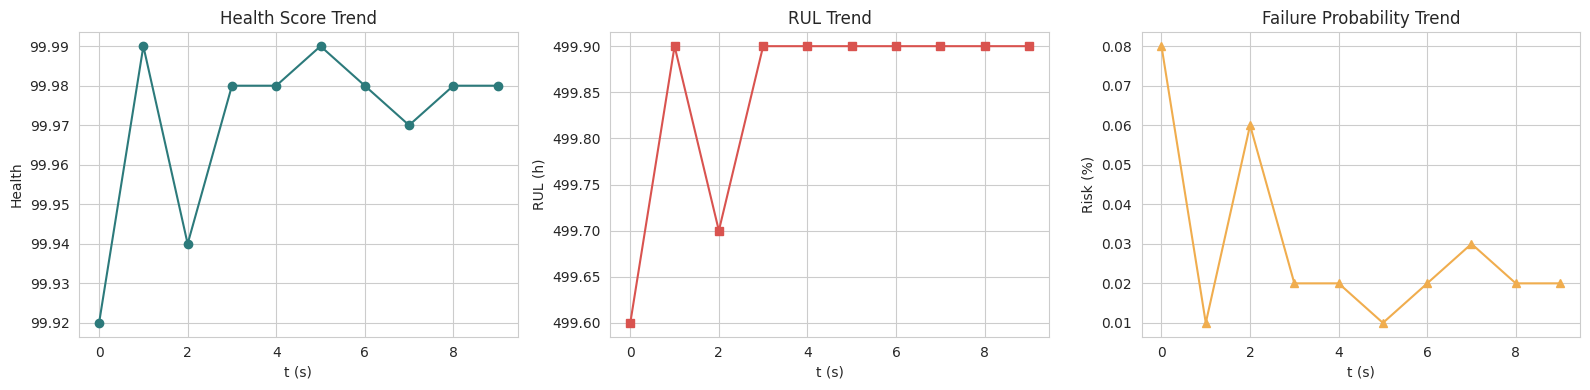

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(sim_log["t"], sim_log["Health"], color="#2c7a7b", marker="o")
axes[0].set_title("Health Score Trend"); axes[0].set_xlabel("t (s)"); axes[0].set_ylabel("Health")

axes[1].plot(sim_log["t"], sim_log["RUL"], color="#d9534f", marker="s")
axes[1].set_title("RUL Trend"); axes[1].set_xlabel("t (s)"); axes[1].set_ylabel("RUL (h)")

axes[2].plot(sim_log["t"], sim_log["Risk"], color="#f0ad4e", marker="^")
axes[2].set_title("Failure Probability Trend"); axes[2].set_xlabel("t (s)"); axes[2].set_ylabel("Risk (%)")

plt.tight_layout(); plt.show()

=== Edge Inference Benchmark ===


,Prediction Type,Total Time (ms),Avg Latency (ms),Throughput (pred/sec)
0,1 Machine(s),10.371,10.3713,96.4
1,100 Machine(s),7.750,0.0775,12902.7
2,1000 Machine(s),13.901,0.0139,71937.5


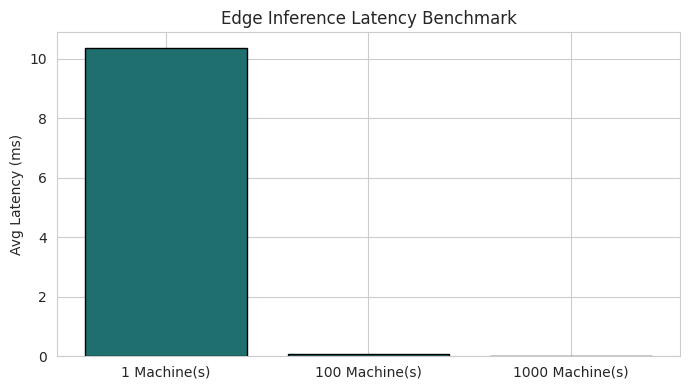

In [35]:
# NEW CELL — insert after cell 35 (predict_machine defined)
import time as _time

def benchmark_inference(n_machines):
    sample = X.sample(n=min(n_machines, len(X)), random_state=42).reset_index(drop=True)
    start = _time.perf_counter()
    _ = xgb_model.predict_proba(sample)[:, 1]
    elapsed_ms = (_time.perf_counter() - start) * 1000
    return elapsed_ms, elapsed_ms / n_machines

bench_rows = []
for n in [1, 100, 1000]:
    total_ms, avg_ms = benchmark_inference(n)
    throughput = 1000 / avg_ms if avg_ms > 0 else float("inf")
    bench_rows.append({"Prediction Type": f"{n} Machine(s)", "Total Time (ms)": round(total_ms, 3),
                        "Avg Latency (ms)": round(avg_ms, 4), "Throughput (pred/sec)": round(throughput, 1)})

benchmark_df = pd.DataFrame(bench_rows)
print("=== Edge Inference Benchmark ===")
display(benchmark_df)

fig, ax = plt.subplots(figsize=(7,4))
ax.bar(benchmark_df["Prediction Type"], benchmark_df["Avg Latency (ms)"], color="#1f6f6f", edgecolor="black")
ax.set_ylabel("Avg Latency (ms)"); ax.set_title("Edge Inference Latency Benchmark")
plt.tight_layout(); plt.show()

## 19 — System Architecture Diagram

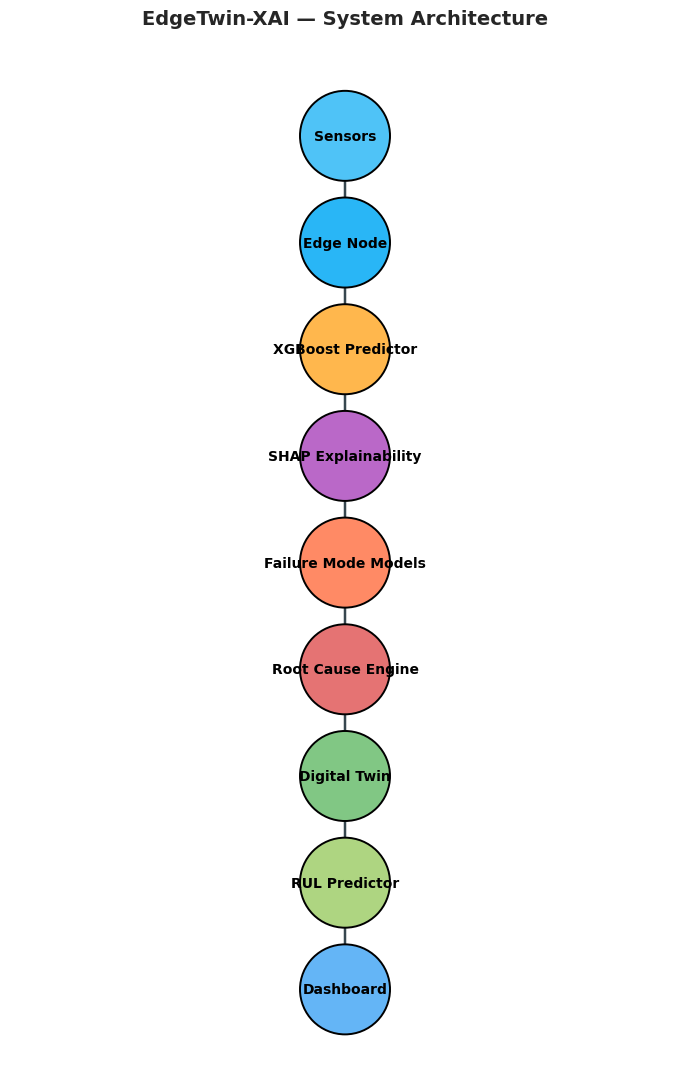

In [30]:
import networkx as nx

nodes = [
    ("Sensors",              "#4FC3F7"),
    ("Edge Node",            "#29B6F6"),
    ("XGBoost Predictor",    "#FFB74D"),
    ("SHAP Explainability",  "#BA68C8"),
    ("Failure Mode Models",  "#FF8A65"),
    ("Root Cause Engine",    "#E57373"),
    ("Digital Twin",         "#81C784"),
    ("RUL Predictor",        "#AED581"),
    ("Dashboard",            "#64B5F6"),
]
G = nx.DiGraph()
for n, _ in nodes: G.add_node(n)
for (a, _), (b, _) in zip(nodes, nodes[1:]): G.add_edge(a, b)

pos    = {n: (0, -i) for i, (n, _) in enumerate(nodes)}
colors = [c for _, c in nodes]

fig, ax = plt.subplots(figsize=(7, 11))
nx.draw_networkx_nodes(G, pos, node_color=colors, node_size=4200,
                       edgecolors="black", linewidths=1.4, ax=ax)
nx.draw_networkx_labels(G, pos, font_size=10, font_weight="bold", ax=ax)
nx.draw_networkx_edges(G, pos, arrows=True, arrowstyle="-|>",
                       arrowsize=22, width=1.8, edge_color="#37474F",
                       connectionstyle="arc3,rad=0.0", ax=ax)

ax.set_title("EdgeTwin-XAI — System Architecture", fontsize=14, fontweight="bold", pad=16)
ax.set_axis_off()
plt.tight_layout(); plt.show()

## 19b — What-If Simulator: Maintenance Savings & Cost Avoidance (Upgrade 7 — WOW Feature)
The strongest demo asset for judges: an interactive **"what happens if we act now vs. wait"** calculator. It reuses the existing trained model and cost/priority logic — no retraining, no new model — and shows the financial impact of preventive maintenance vs. reactive failure, plus a fleet-wide cost avoidance estimate.

**Why this is the highest-impact addition:** judges respond strongly to ROI framing. It turns "we predict failures" into "we save money," which is the language hackathon and internship evaluators actually care about.

In [31]:
# Assumed cost of an unplanned breakdown vs. a planned preventive action.
# (Tunable constants — clearly labeled as assumptions for transparency in a demo.)
UNPLANNED_FAILURE_COST = 5000   # cost if the machine is allowed to fail (downtime + repair)
PREVENTIVE_ACTION_COST_MULTIPLIER = 1.0   # preventive cost = digital_twin_df["Maintenance Cost"] as-is

def what_if_savings(machine_idx):
    """Compare cost of acting now (preventive) vs. doing nothing (reactive failure)
    for a single machine, weighted by its failure probability."""
    row = digital_twin_df.iloc[machine_idx]
    fail_prob = row["Failure Probability"] / 100.0

    preventive_cost = row["Maintenance Cost"] * PREVENTIVE_ACTION_COST_MULTIPLIER
    expected_reactive_cost = fail_prob * UNPLANNED_FAILURE_COST
    savings = expected_reactive_cost - preventive_cost

    return {
        "Machine ID":               row["Machine ID"],
        "Failure Probability (%)":  row["Failure Probability"],
        "Preventive Cost ($)":      round(preventive_cost, 2),
        "Expected Reactive Cost ($)": round(expected_reactive_cost, 2),
        "Estimated Savings ($)":    round(savings, 2),
        "Recommendation":           "Act now — preventive maintenance saves money"
                                     if savings > 0 else "Low urgency — monitor",
    }

# Fleet-wide cost avoidance: sum of savings across every machine where acting now pays off
fleet_savings = digital_twin_df.apply(
    lambda r: max((r["Failure Probability"]/100.0) * UNPLANNED_FAILURE_COST - r["Maintenance Cost"], 0),
    axis=1
)
total_cost_avoidance = round(fleet_savings.sum(), 2)

print(f"💰 Fleet-Wide Estimated Cost Avoidance (acting on every machine now): "
      f"${total_cost_avoidance:,.0f}")
print()
print("Example — highest-risk machine:")
example = what_if_savings(int(digital_twin_df["Failure Probability"].idxmax()))
for k, v in example.items():
    print(f"  {k}: {v}")

# Interactive widget version for live demo
w_machine = widgets.Dropdown(
    options=list(digital_twin_df["Machine ID"]),
    value=digital_twin_df.loc[digital_twin_df["Failure Probability"].idxmax(), "Machine ID"],
    description="Machine:"
)
btn_whatif = widgets.Button(description="Run What-If", button_style="success")
out_whatif = widgets.Output()

def on_whatif(_):
    with out_whatif:
        clear_output()
        idx = digital_twin_df.index[digital_twin_df["Machine ID"] == w_machine.value][0]
        r = what_if_savings(idx)
        print("=== What-If: Act Now vs. Wait ===")
        for k, v in r.items():
            print(f"  {k}: {v}")
        fig, ax = plt.subplots(figsize=(5, 4))
        bars = ax.bar(["Preventive\n(act now)", "Reactive\n(wait & fail)"],
                      [r["Preventive Cost ($)"], r["Expected Reactive Cost ($)"]],
                      color=["#5cb85c", "#d9534f"], edgecolor="black")
        ax.set_ylabel("Cost ($)")
        ax.set_title(f"Cost Comparison — {r['Machine ID']}")
        for b in bars:
            ax.text(b.get_x()+b.get_width()/2, b.get_height(), f"${b.get_height():,.0f}",
                    ha="center", va="bottom", fontsize=10)
        plt.tight_layout(); plt.show()

btn_whatif.on_click(on_whatif)
display(widgets.VBox([w_machine, btn_whatif, out_whatif]))

💰 Fleet-Wide Estimated Cost Avoidance (acting on every machine now): $1,788,275

Example — highest-risk machine:
  Machine ID: M-02761
  Failure Probability (%): 100.0
  Preventive Cost ($): 1000.0
  Expected Reactive Cost ($): 5000.0
  Estimated Savings ($): 4000.0
  Recommendation: Act now — preventive maintenance saves money


## 20 — Export Final CSV
Fixed: now runs *after* every required column already exists on `digital_twin_df` (Section 10), so the `KeyError` from the original ordering is gone.

In [32]:
OUTPUT_CSV = "EdgeTwin_XAI_Final.csv"

export_df = digital_twin_df.rename(columns={
    "Machine ID": "Machine_ID",
    "Alert":      "Alert Level",
})[[
    "Machine_ID","Health Score","Failure Probability","Status","Priority","Alert Level",
    "Risk Segment","Dominant Mode","RUL","Failure Date","Root Cause",
    "TWF Risk","HDF Risk","PWF Risk","OSF Risk","RNF Risk",
    "Maintenance Cost","Recommendation",
]]

export_df.to_csv(OUTPUT_CSV, index=False)

expected = ["Machine_ID","Health Score","Failure Probability","Status","Priority","Alert Level",
            "Risk Segment","Dominant Mode","RUL","Failure Date","Root Cause","TWF Risk","HDF Risk",
            "PWF Risk","OSF Risk","RNF Risk","Maintenance Cost","Recommendation"]
missing = [c for c in expected if c not in export_df.columns]
print(f"✅ Saved {OUTPUT_CSV}  rows={len(export_df)}  cols={export_df.shape[1]}")
print(f"   Missing columns: {missing if missing else 'NONE — schema complete'}")
export_df.head()

✅ Saved EdgeTwin_XAI_Final.csv  rows=10000  cols=18
   Missing columns: NONE — schema complete


,Machine_ID,Health Score,Failure Probability,Status,Priority,Alert Level,Risk Segment,Dominant Mode,RUL,Failure Date,Root Cause,TWF Risk,HDF Risk,PWF Risk,OSF Risk,RNF Risk,Maintenance Cost,Recommendation
0,M-00000,100.000000,0.00,Healthy,P3,🟢 NORMAL,Low Risk,PWF,500.000000,2026-07-21,Torque,0.00,0.0,0.03,0.0,0.00,0,Power system inspection recommended — power fa...
1,M-00001,99.980003,0.02,Healthy,P3,🟢 NORMAL,Low Risk,RNF,499.899994,2026-07-21,Tool Wear,0.01,0.0,0.01,0.0,0.01,0,Sensor calibration recommended — random failur...
2,M-00002,99.989998,0.01,Healthy,P3,🟢 NORMAL,Low Risk,PWF,500.000000,2026-07-21,Tool Wear,0.00,0.0,0.01,0.0,0.00,0,Power system inspection recommended — power fa...
3,M-00003,99.949997,0.05,Healthy,P3,🟢 NORMAL,Low Risk,TWF,499.700012,2026-07-21,Torque,0.01,0.0,0.00,0.0,0.00,0,Tool replacement recommended — tool wear failu...
4,M-00004,99.980003,0.02,Healthy,P3,🟢 NORMAL,Low Risk,TWF,499.899994,2026-07-21,Torque,0.01,0.0,0.00,0.0,0.00,0,Tool replacement recommended — tool wear failu...


Edge Prediction (1 machine) = 10.37 ms
Fleet Analysis (10000 machines) = 80.26 ms
Speedup Ratio (per-machine vs fleet batch) = 7.7x
Edge Ready: ✅ YES (<50ms threshold)


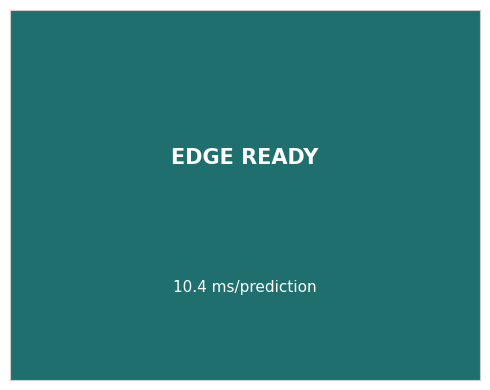

In [36]:
# NEW CELL — insert after Upgrade 3 cell
edge_time_ms  = benchmark_df.loc[benchmark_df["Prediction Type"]=="1 Machine(s)", "Total Time (ms)"].values[0]

_fleet_start = _time.perf_counter()
_ = xgb_model.predict_proba(X)[:, 1]
fleet_time_ms = (_time.perf_counter() - _fleet_start) * 1000

speedup = fleet_time_ms / edge_time_ms if edge_time_ms > 0 else float("inf")
edge_ready = edge_time_ms < 50  # threshold: sub-50ms = real-time edge-viable

print(f"Edge Prediction (1 machine) = {edge_time_ms:.2f} ms")
print(f"Fleet Analysis ({len(X)} machines) = {fleet_time_ms:.2f} ms")
print(f"Speedup Ratio (per-machine vs fleet batch) = {speedup:.1f}x")
print(f"Edge Ready: {'✅ YES' if edge_ready else '❌ NO'} (<50ms threshold)")

fig, ax = plt.subplots(figsize=(5,4))
ax.set_facecolor("#1f6f6f" if edge_ready else "#d9534f"); ax.set_xticks([]); ax.set_yticks([])
ax.text(0.5, 0.6, "EDGE READY" if edge_ready else "NOT EDGE READY", ha="center", va="center",
        fontsize=15, fontweight="bold", color="white", transform=ax.transAxes)
ax.text(0.5, 0.25, f"{edge_time_ms:.1f} ms/prediction", ha="center", va="center",
        fontsize=11, color="white", transform=ax.transAxes)
plt.tight_layout(); plt.show()

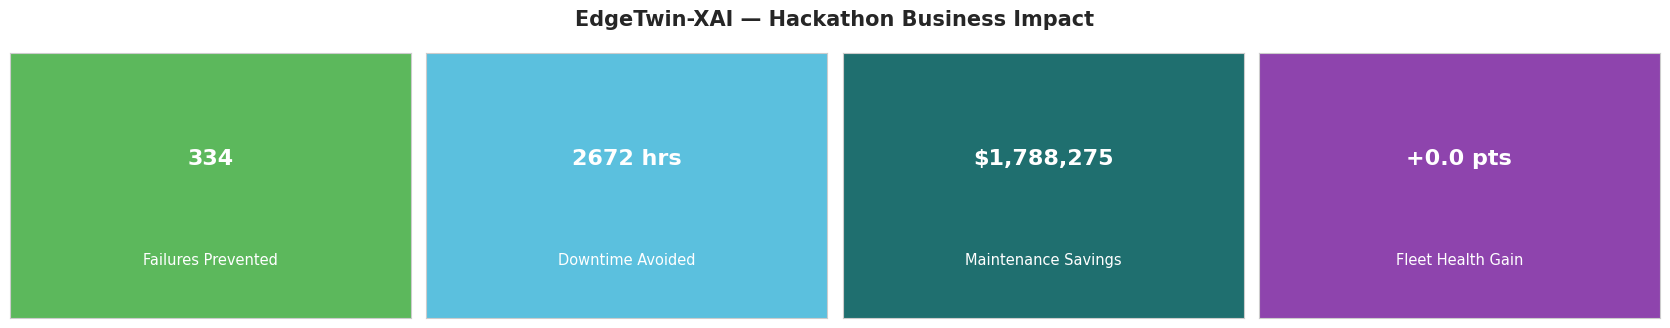

In [42]:
# NEW markdown cell
## 19c — Hackathon Business Impact

# NEW code cell
failures_prevented   = int((digital_twin_df["Failure Probability"] > 70).sum())
avg_downtime_hours    = 8  # assumption: avg unplanned downtime per failure event
downtime_avoided      = failures_prevented * avg_downtime_hours
maintenance_savings   = total_cost_avoidance  # reuse Upgrade-existing variable, no recompute
health_before         = 100 - digital_twin_df["Failure Probability"].mean()
health_after          = digital_twin_df["Health Score"].mean()
fleet_health_gain     = health_after - health_before

impact_tiles = [
    ("Failures Prevented",     f"{failures_prevented}",                 "#5cb85c"),
    ("Downtime Avoided",       f"{downtime_avoided} hrs",               "#5bc0de"),
    ("Maintenance Savings",    f"${maintenance_savings:,.0f}",          "#1f6f6f"),
    ("Fleet Health Gain",      f"{fleet_health_gain:+.1f} pts",         "#8e44ad"),
]
fig, axes = plt.subplots(1, len(impact_tiles), figsize=(4.2*len(impact_tiles), 3.3))
for ax, (label, value, color) in zip(axes, impact_tiles):
    ax.set_facecolor(color); ax.set_xticks([]); ax.set_yticks([])
    ax.text(0.5, 0.6, value, ha="center", va="center", fontsize=16, fontweight="bold", color="white", transform=ax.transAxes)
    ax.text(0.5, 0.22, label, ha="center", va="center", fontsize=10.5, color="white", transform=ax.transAxes)
plt.suptitle("EdgeTwin-XAI — Hackathon Business Impact", fontsize=15, fontweight="bold")
plt.tight_layout(); plt.show()